In [2]:
import glob
import os

import numpy as np
import cv2
import matplotlib.pyplot as plt
from tqdm import tqdm

import sys
sys.path.append("../../researches/objectdetectionmetrics/")
from metricsevaluator import MetricsEvaluator

In [24]:
model_path = "/home/kyamkovyi/projects/pointgrab/code/cp-core/models/obj-det/yolov7-tiny-deploy-pg.onnx"

INPUT_WIDTH = 640
INPUT_HEIGHT = 640
CONFIDENCE_THRESHOLD = 0.4

NMS_THRESHOLD = 0.45

classes = ["TABLE", "CHAIR", "LAPTOP"]

In [100]:
def post_process(input_image, outputs, conf_th=CONFIDENCE_THRESHOLD, nms_th=NMS_THRESHOLD):
    ratioh = input_image.shape[0] / INPUT_HEIGHT
    ratiow = input_image.shape[1] / INPUT_WIDTH

    confidences = []
    boxes = []
    class_ids = []

    for pdata in outputs:
        box_score = pdata[4]
        if box_score <= conf_th:
            continue
        scores = pdata[5:]
        classIdPoint = np.argmax(scores)
        max_class_socre = scores[classIdPoint]
        max_class_socre *= box_score

        if max_class_socre <= conf_th:
            continue

        cx = pdata[0] * ratiow
        cy = pdata[1] * ratioh
        w = pdata[2] * ratiow
        h = pdata[3] * ratioh

        left = int(cx - 0.5 * w);
        top = int(cy - 0.5 * h);

        confidences.append(max_class_socre);
        boxes.append((left, top, int(w), int(h)))
        class_ids.append(classIdPoint)
    
    indices = cv2.dnn.NMSBoxes(boxes, confidences, conf_th, nms_th)
    # for i in indices:
    #     box = boxes[i]
    #     left = box[0]
    #     top = box[1]
    #     width = box[2]
    #     height = box[3]             
    #     # Draw bounding box.             
    #     cv2.rectangle(input_image, (left, top), (left + width, top + height), BLUE, 3*THICKNESS)
    #     # Class label.                      
    #     label = "{}:{:.2f}".format(classes[class_ids[i]], confidences[i])             
    #     # Draw label.             
    #     draw_label(input_image, label, left, top)
    return np.array(boxes)[indices], np.array(class_ids)[indices], np.array(confidences)[indices]

In [96]:
tst_img_paths = sorted(glob.glob("../../../db/ObjectDetectionV2/data/datasets/yolov7/images/test/*.jpg"))
len(tst_img_paths)

54

In [97]:
model = cv2.dnn.readNet(model_path)

[[224 174 123  75]
 [ 12 393 241  87]
 [170  28 309 227]
 [180 321 112 143]
 [150 385  93  96]]


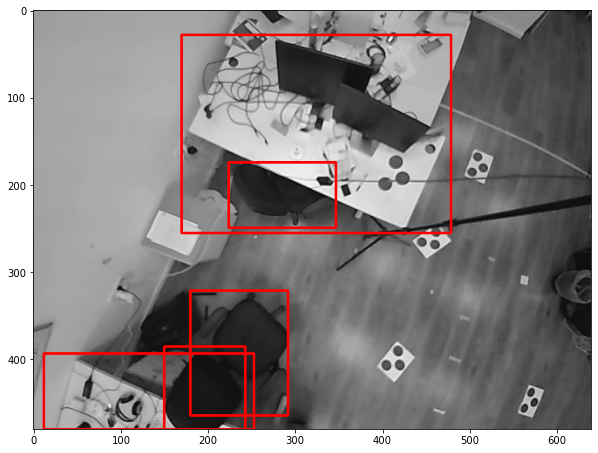

In [98]:
img = cv2.imread(tst_img_paths[0])

blob = cv2.dnn.blobFromImage(img, 1 / 255.0, (INPUT_WIDTH, INPUT_HEIGHT), (0,0,0), False, crop=False)

# set input blob for the network
model.setInput(blob)

# Run the forward pass to get output of the output layers.
outputs = model.forward(model.getUnconnectedOutLayersNames())

res = post_process(img.copy(), outputs[0][0])
print(res[0])

tmp = img.copy()
for box in res[0]:
    cv2.rectangle(tmp, box[:2].astype(int), box[:2].astype(int) + box[2:].astype(int), (255, 0, 0), 2)

plt.figure(figsize=(10, 10))
plt.imshow(tmp);

In [22]:
tst_labels_pths = sorted(glob.glob("../../../db/ObjectDetectionV2/data/datasets/yolov7/labels/test/*.txt"))
len(tst_labels_pths)

54

100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 54/54 [00:05<00:00,  9.06it/s]


CHAIR: P = 0.922. R = 0.866. F1 = 0.893. AP = 0.857
LAPTOP: P = 0.910. R = 0.847. F1 = 0.877. AP = 0.834
TABLE: P = 0.864. R = 0.902. F1 = 0.883. AP = 0.865


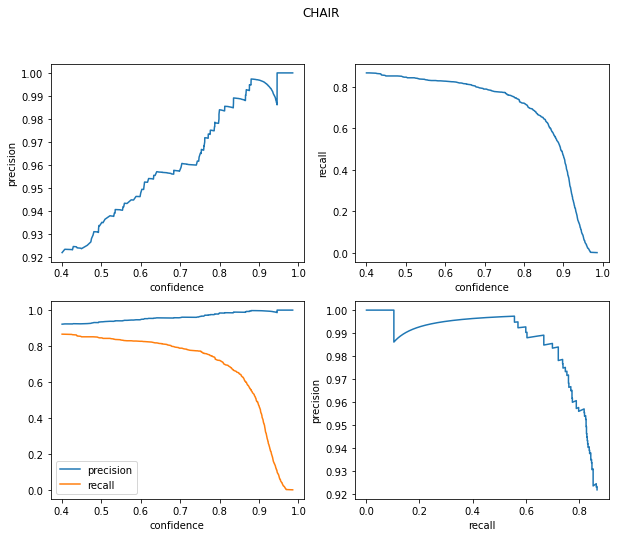

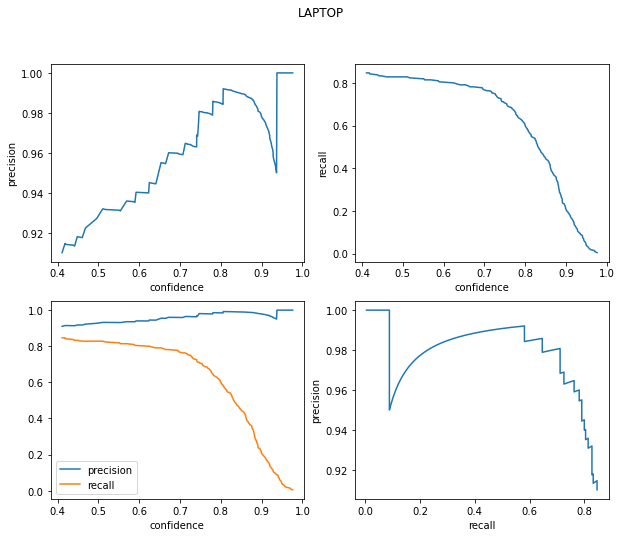

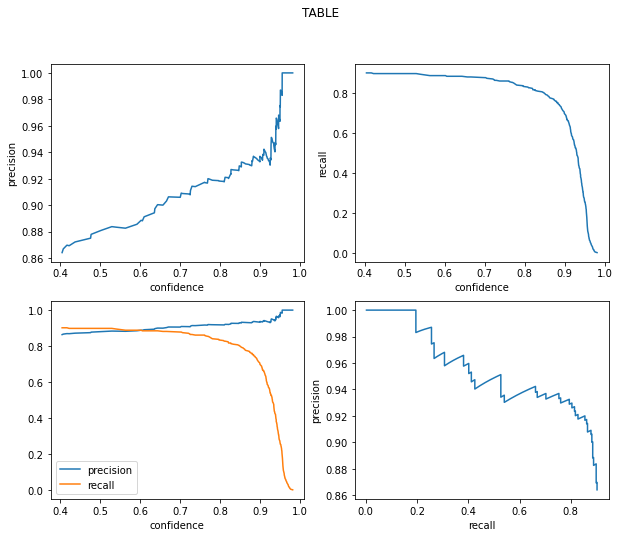

In [119]:
# positions

CONF_TH = 0.4

# init evaluator
evaluator = MetricsEvaluator(
    is_relative_coordinates=True,
    is_xywh_coordinates=True,
    img_size=(INPUT_WIDTH, INPUT_HEIGHT),
    outpath="."
)

for label_pth in tst_labels_pths:
    img_name = os.path.basename(label_pth).split(".")[0]

    with open(label_pth, "rt") as f:
        lines = f.readlines()
    
    for line in lines:
        c, x_c, y_c, w, h = [float(i) for i in line[:-1].split()] 
        x = x_c - w / 2
        y = y_c - h / 2
        
        evaluator.add_gt_box(
            img_path=img_name,
            class_name=classes[int(c)],
            bbox=[x_c, y_c, w, h]
        )
    # break

for img_pth in tqdm(tst_img_paths):
    img_name = os.path.basename(img_pth).split(".")[0]
    
    img = cv2.imread(img_pth)
    h, w, _ = img.shape
    blob = cv2.dnn.blobFromImage(img, 1 / 255.0, (INPUT_WIDTH, INPUT_HEIGHT), (0,0,0), False, crop=False)
    # set input blob for the network
    model.setInput(blob)
    # Run the forward pass to get output of the output layers.
    outputs = model.forward(model.getUnconnectedOutLayersNames())
    res = post_process(img.copy(), outputs[0][0], CONF_TH, 0.45)

    for box, cl, conf in zip(*res):
        evaluator.add_det_box(
            img_path=img_name,
            class_name=classes[cl],
            bbox=(box + [box[2] / 2, box[3] / 2, 0, 0]) / [w, h, w, h],
            confidence=conf
        )
    # break

results = evaluator.eval_conf_vals(0.5)

for result in results:
    precision = result["total TP"] / (result["total TP"] + result["total FP"])
    recall = result["total TP"] / (result["total positives"])

    f_score = 2 * precision * recall / (precision + recall)
    print(f"{result['class']}: P = {precision:.03f}. R = {recall:.03f}. F1 = {f_score:.03f}. AP = {result['AP']:.03f}")

    plt.figure(figsize=(10, 8))
    # plt.title(result['class'])
    plt.suptitle(result['class'])
    plt.subplot(2, 2, 1)
    plt.plot(result["confidence"], result["precision"])
    plt.xlabel("confidence")
    plt.ylabel("precision")

    plt.subplot(2, 2, 2)
    plt.plot(result["confidence"], result["recall"])
    plt.xlabel("confidence")
    plt.ylabel("recall")

    plt.subplot(2, 2, 3)
    plt.plot(result["confidence"], result["precision"], label="precision")
    plt.plot(result["confidence"], result["recall"], label="recall")
    # plt.title("exp5")
    # plt.vlines(0.11, 0, 1, label="0.11", colors="r")

    plt.xlabel("confidence")
    plt.legend()

    plt.subplot(2, 2, 4)
    plt.plot(result["recall"], result["precision"])
    plt.xlabel("recall")
    plt.ylabel("precision")


In [85]:
# tmp = cv2.imread(img_pth)
# tmp = cv2.resize(tmp, (INPUT_WIDTH, INPUT_HEIGHT))
# for box in evaluator._all_bounding_boxes._boundingBoxes:
#     if box._bbType.value == 1:
#         c = (0, 255, 0)
#     else:
#         c = (255, 0, 0)
#     cv2.rectangle(tmp, (box._x, box._y), (box._x2, box._y2), c, 3)

# plt.figure(figsize=(10, 10))
# plt.imshow(tmp)